In [1]:
import importlib
import analysis
importlib.reload(analysis)


import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
import pandas as pd

# HG Gain Test

Processant 16 canals...


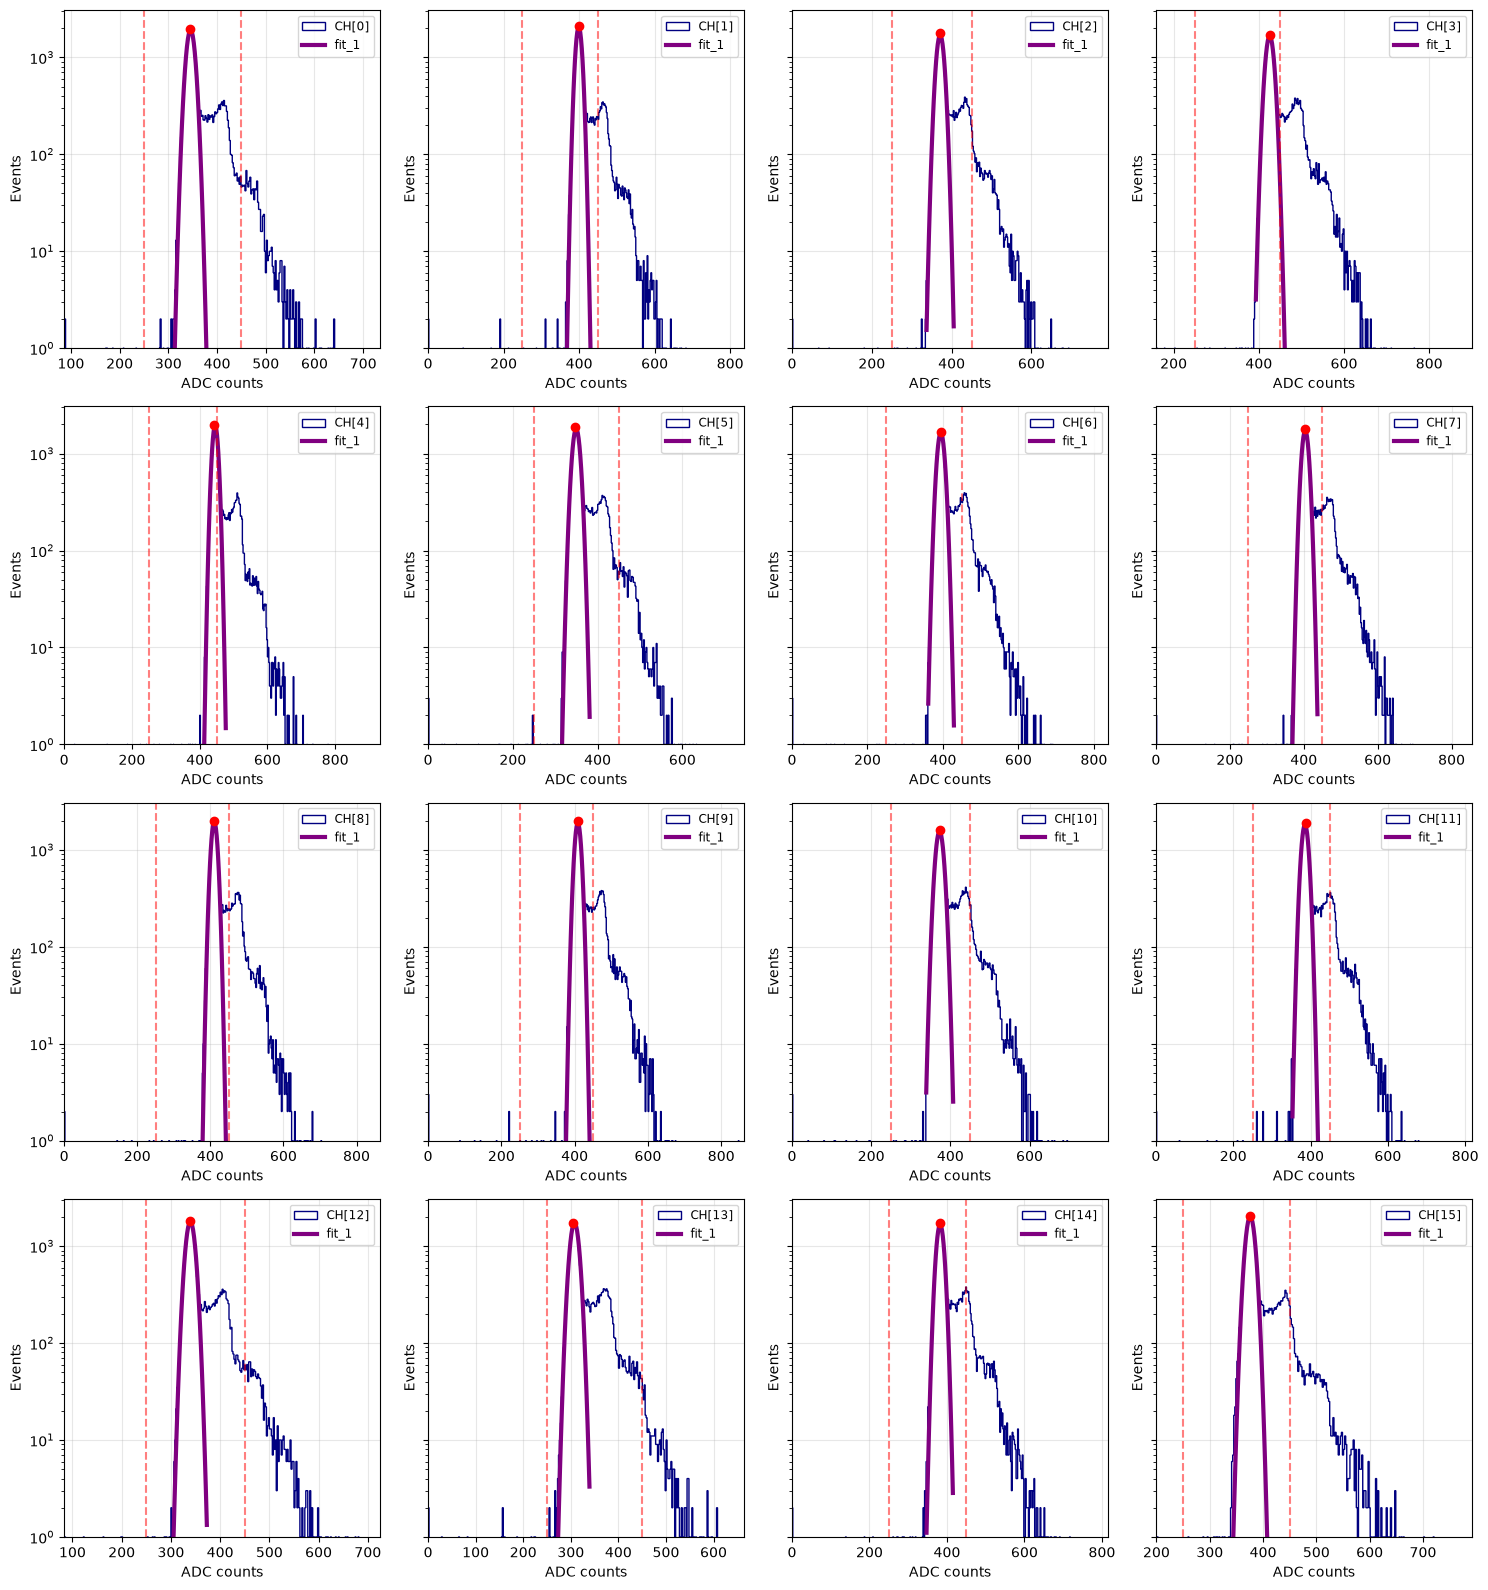

Espectres guardats a: HG_espectres_pedestal.txt


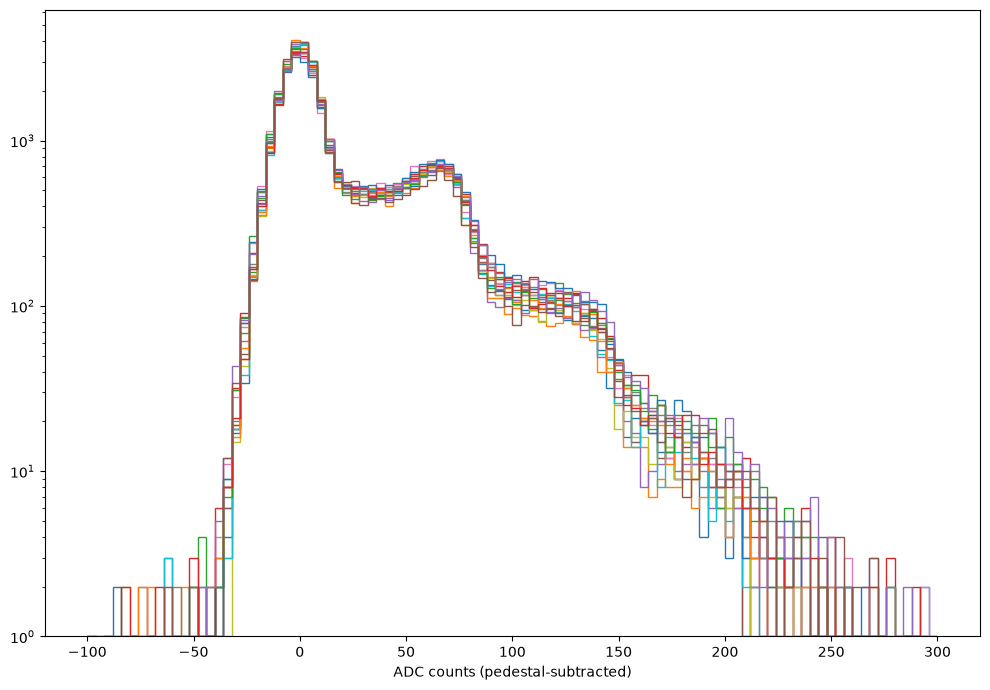

In [2]:
ruta = "Data/pedestal_LaBr_fpga_HG1_36.5V_30sec.txt"

df = analysis.cargar_canales_separados(ruta, 1)

mis_labels = [f"CH[{i}]" for i in range(16)]


xl_pedestal = 250
xr_pedestal = 450
fit_bool_gauss = True


pos_pedestal_A, sigma_pedestal_A, area_promig_A = analysis.plot_acq_pedestal(df, mis_labels, fit_bool_gauss, xl_pedestal, xr_pedestal,100,10)

# Pedestal

Processant 16 canals...


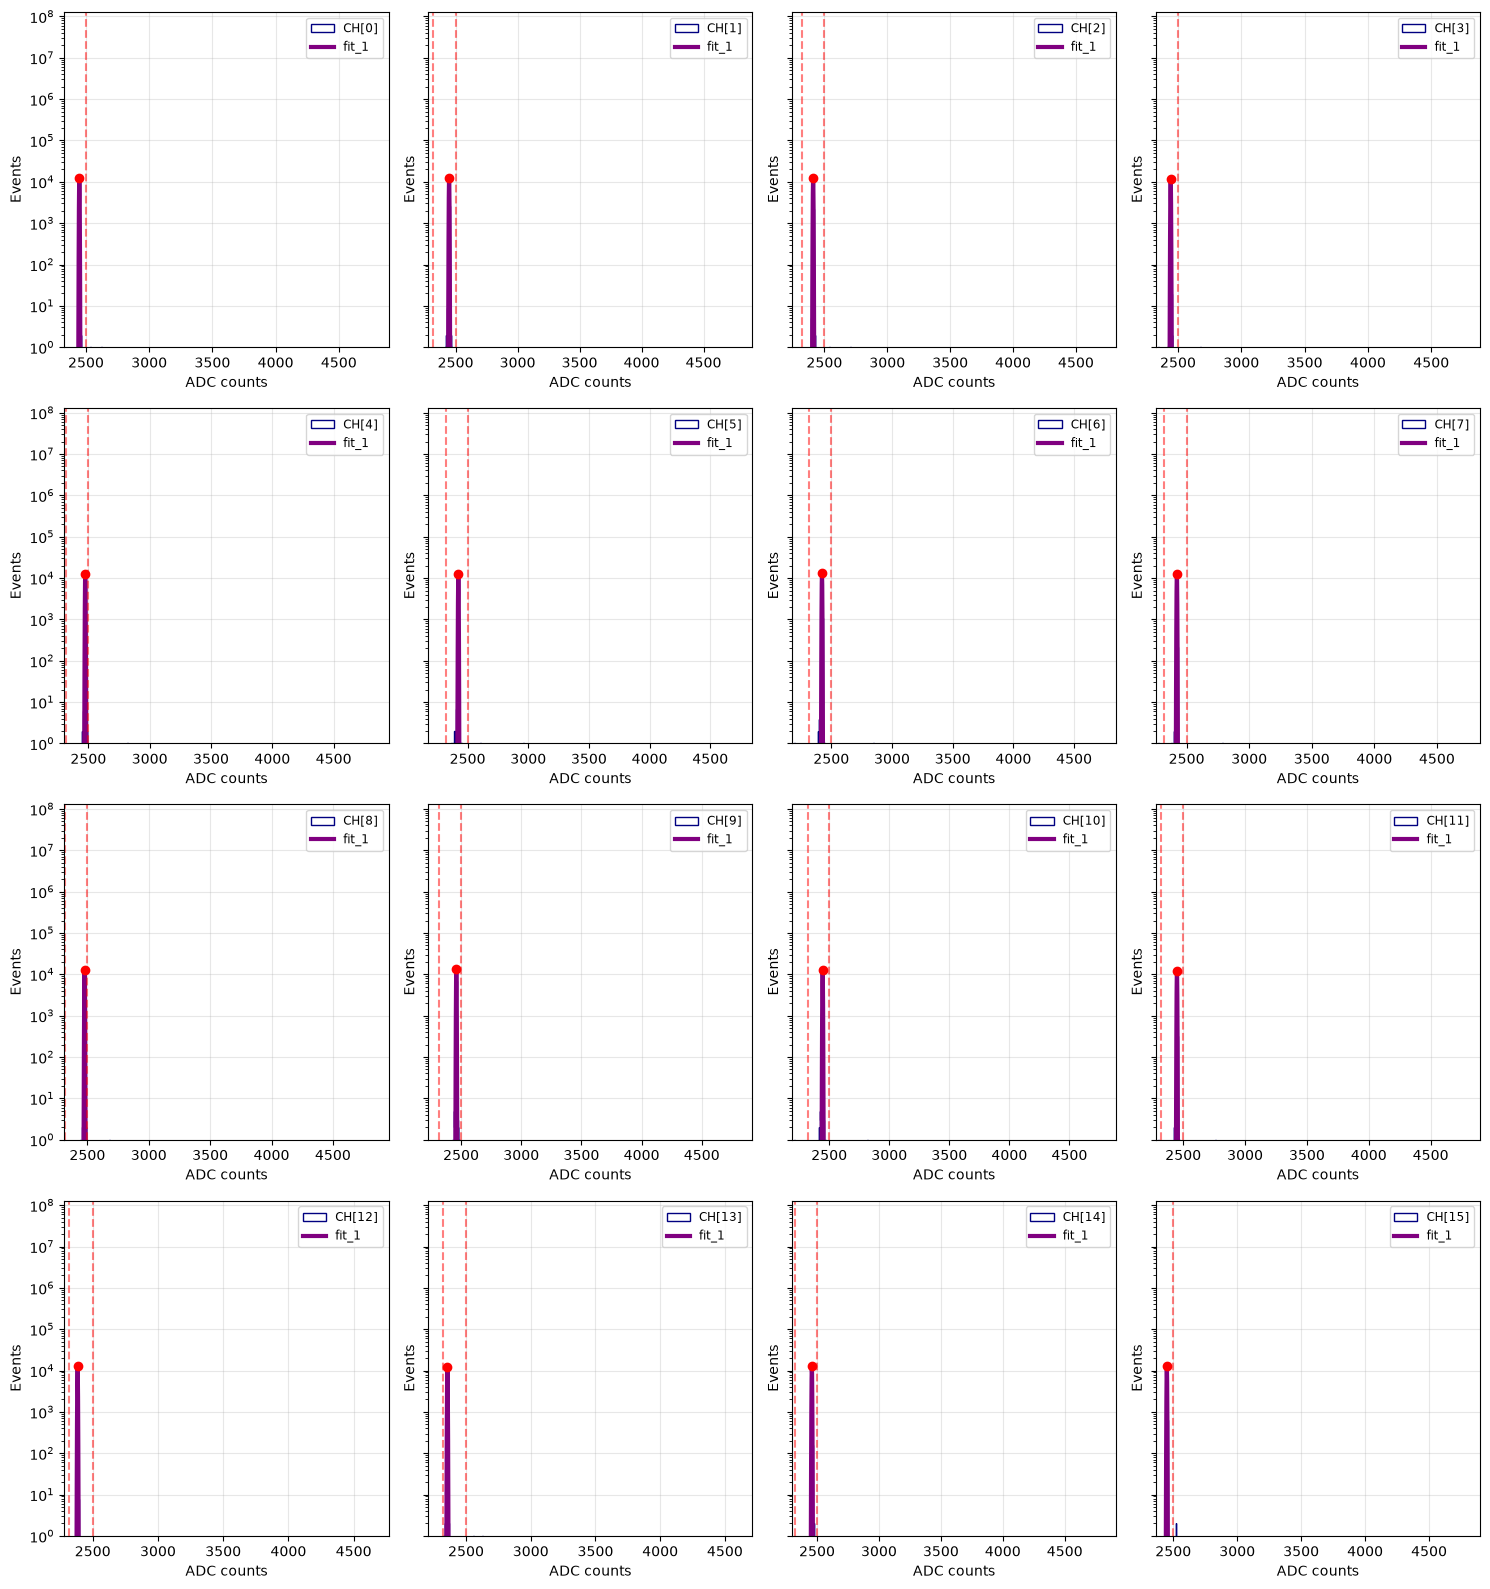

Espectres guardats a: HG_espectres_pedestal.txt


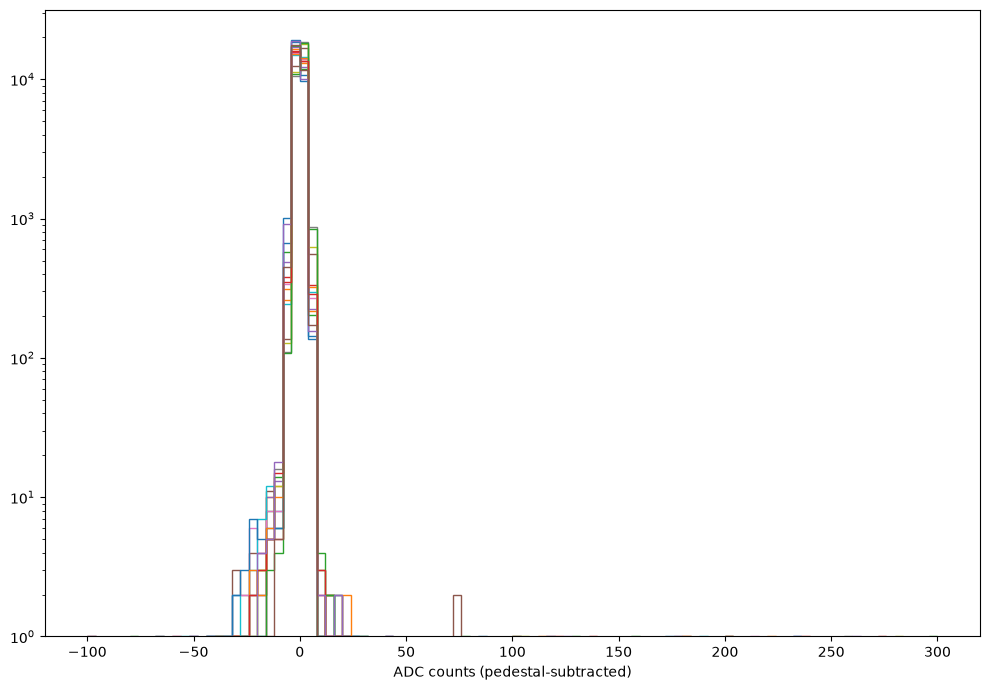

In [3]:
ruta = "Data/pedestal_LaBr_fpga_LG12_36.5V_30sec.txt"


df = analysis.cargar_canales_separados(ruta,1)


mis_labels = [f"CH[{i}]" for i in range(len(df))]

xl=2320
xr=2500
fit_bool_gauss = True


if fit_bool_gauss == True:
    pos_pedestal,sigma_pedestal,area_promig = analysis.plot_acq_pedestal(df,mis_labels,fit_bool_gauss,xl,xr,100)

    pos_pedestal = np.array(pos_pedestal)
else:
    analysis.plot_acq_pedestal(df,mis_labels,fit_bool_gauss,xl,xr)

# Net spectra

In [4]:
pics = []

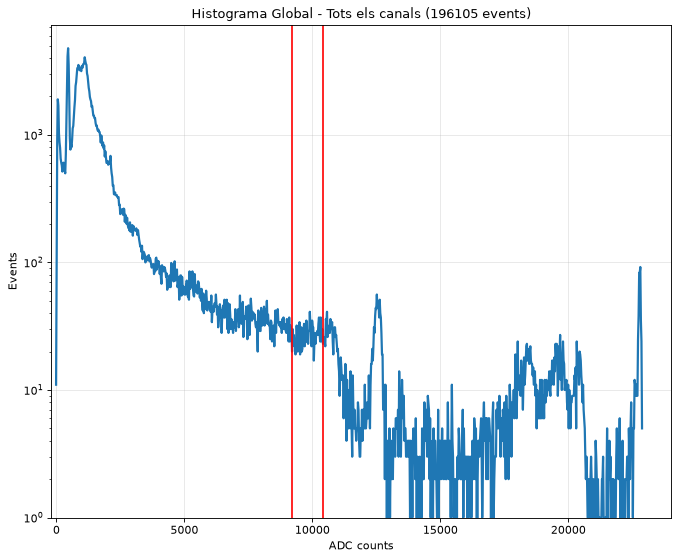

In [8]:
background_file = "Data/fons_LaBr_maj_nmaj4_LG12_36.5V_10800s_merged.txt"

background_bins, background_counts, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta=background_file,
    asicid=1,
    smoothing_points=1,
    xl=9200,
    xr=10400,
    prominence_peak=20,
    fit_bool=False,
    subtract_bool=True,
    background_removal=False,
    pos_pedestal=pos_pedestal
)

ruta_backgr = "Data/fons_LaBr_maj_nmaj4_LG12_36.5V_10800s_merged.txt"

### $^{60}\mathrm{Co}$

--- Ajust (gauss_parab) ---
mu = 10157.926855441892 ± 1.0011424788125503
sigma = 104.1194935580526 ± 1.2332191533331334
resolució = 2.4137077771693316 ± 0.02858959077430573
àrea = 23265.194033630087 ± 350.9635243743617


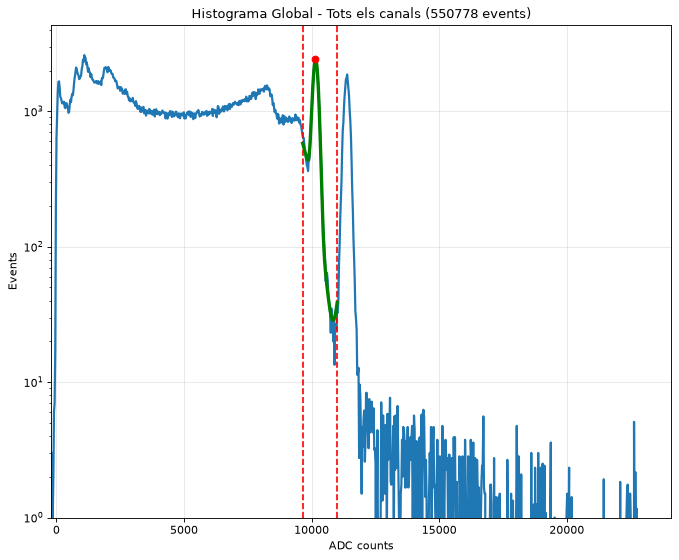

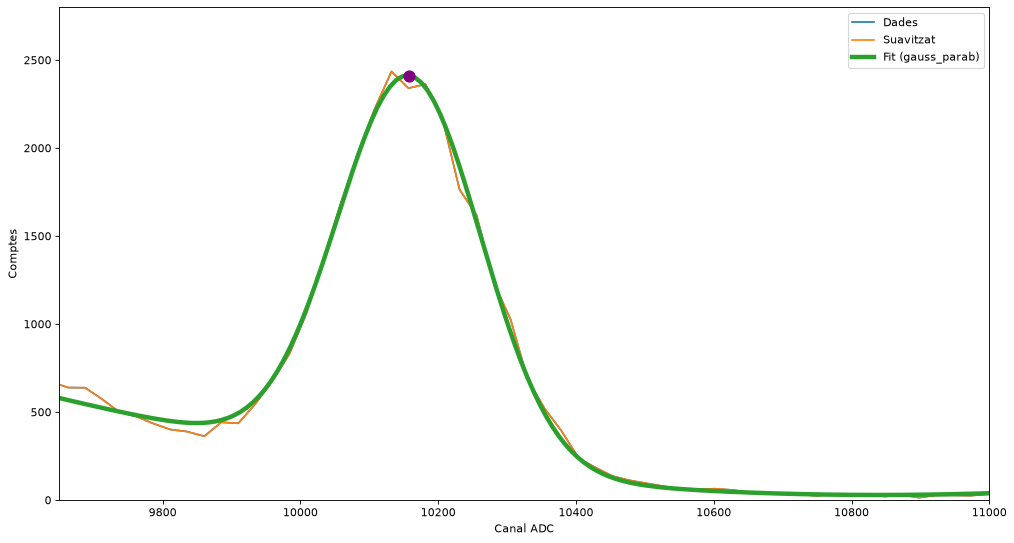

In [9]:
bin_centers_Co, counts_total_Co, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta=r"Data/60Co_LaBr_maj_nmaj4_LG12_36.5V_900s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl=9650,
    xr=11000,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=True,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=900,
    fit_type="gauss_parab",
)

pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

--- Ajust (gauss_parab) ---
mu = 11377.829187686395 ± 0.8140987187237363
sigma = 111.03105412614921 ± 1.0253416513358211
resolució = 2.297961654760421 ± 0.021221689189072534
àrea = 19951.656739251273 ± 234.4869177082329


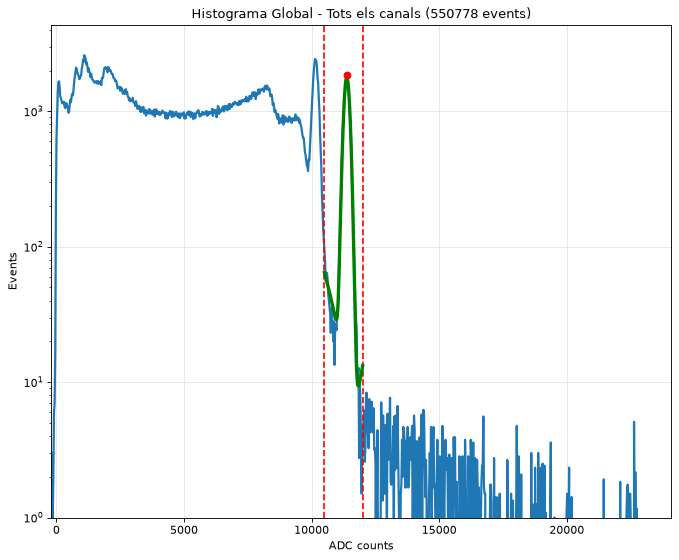

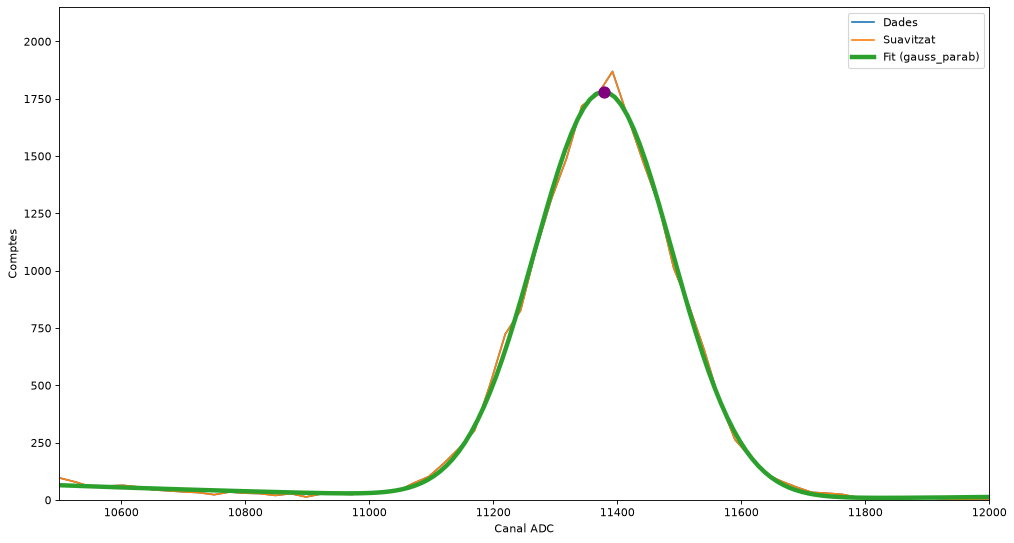

In [10]:
bin_centers, counts_total, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta=r"Data/60Co_LaBr_maj_nmaj4_LG12_36.5V_900s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl=10500,
    xr=12000,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=True,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=900,
    fit_type="gauss_parab",
)

pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

### $^{137}\mathrm{Cs}$

--- Ajust (gauss) ---
mu = 5949.116141696436 ± 0.6858807556429459
sigma = 72.30867133475162 ± 0.7457026642790251
resolució = 2.8621715332670075 ± 0.02951875990798006
àrea = 14888.169964741955 ± 197.7321822805523


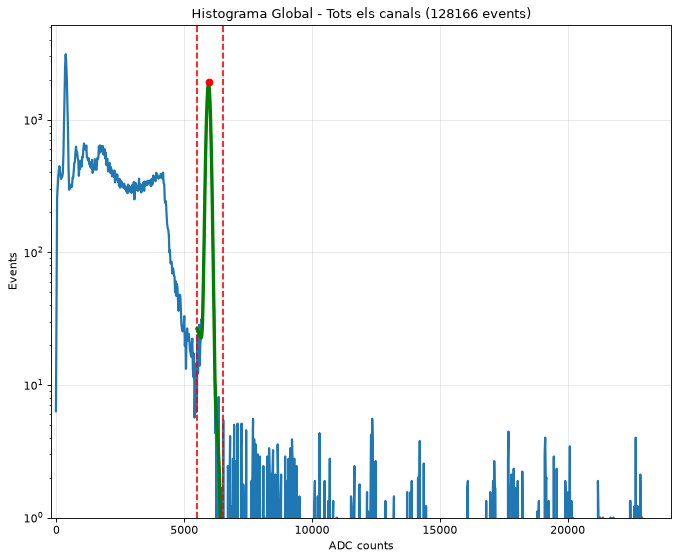

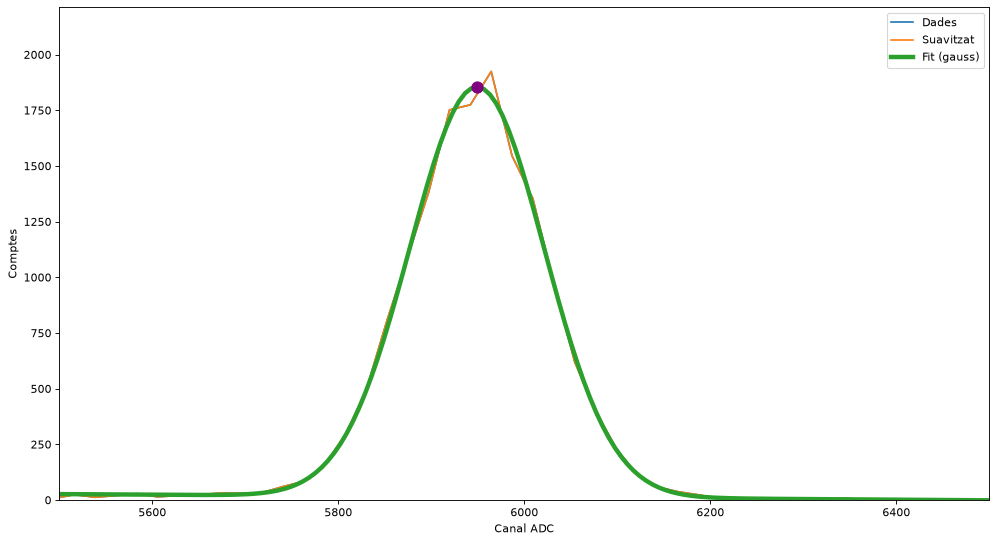

In [25]:
bin_centers_Cs, counts_total_Cs, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta=r"Data/137Cs_LaBr_maj_nmaj4_LG12_36.5V_cgain15_1200s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl=5500,
    xr=6500,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=True,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=1200,
)

pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

### $^{22}\mathrm{Na}$

--- Ajust (gauss) ---
mu = 11077.603792699681 ± 0.85796456463489
sigma = 92.54655702718712 ± 0.9546992862585265
resolució = 1.9673071150083898 ± 0.020295078425016943
àrea = 10657.189776045312 ± 140.17993803128186


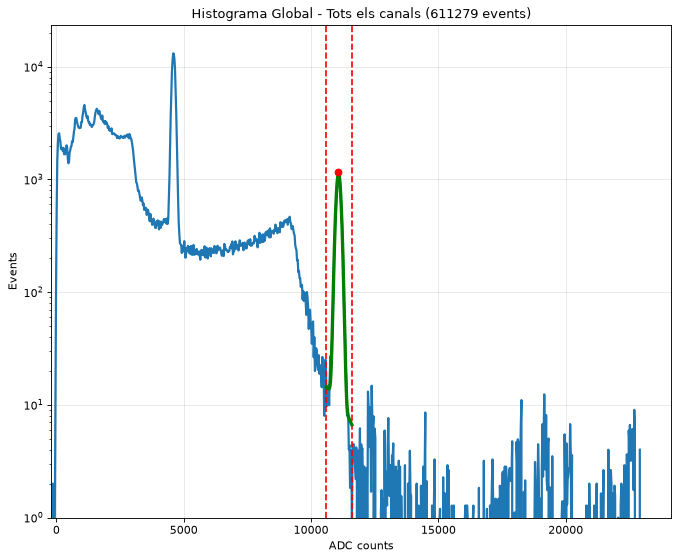

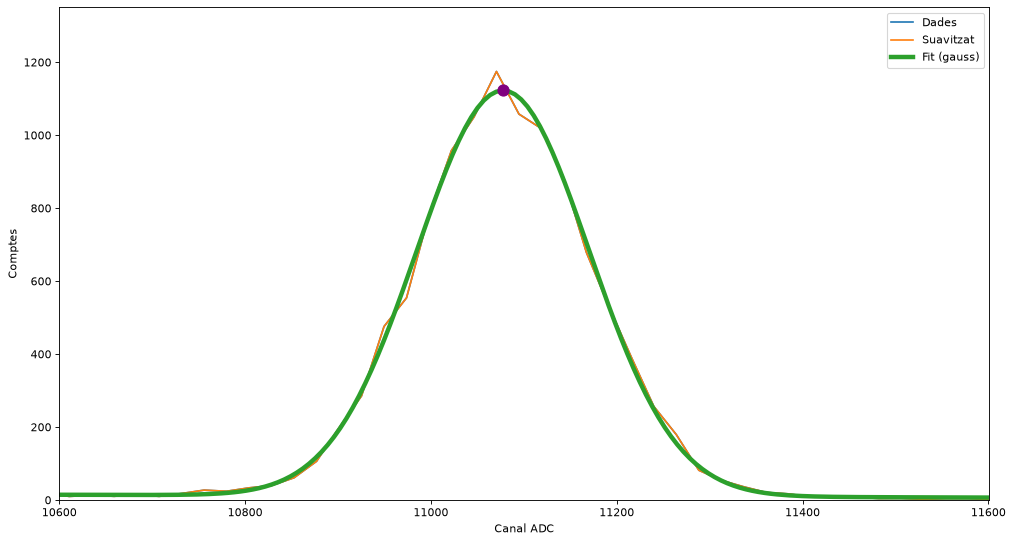

In [12]:
bin_centers_Na, counts_total_Na, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta="Data/22Na_LaBr_maj_nmaj4_LG12_36.5V_3900s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl=10600,
    xr=11601,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=True,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=3900,
)

pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

### $^{241}\mathrm{Am}$

--- Ajust (gauss_parab) ---
mu = 708.9639112710188 ± 1.2410671913745996
sigma = 30.2355677023027 ± 1.655790629035222
resolució = 10.042728517820857 ± 0.5502509289997881
àrea = 132098.36413473828 ± 9186.310440030344


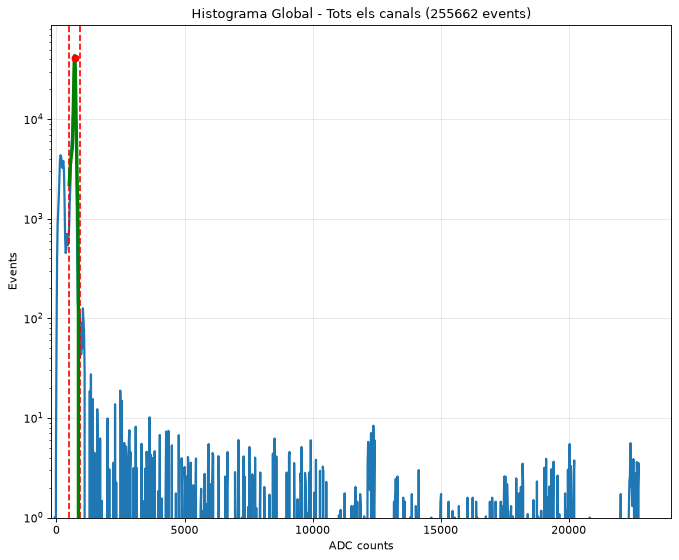

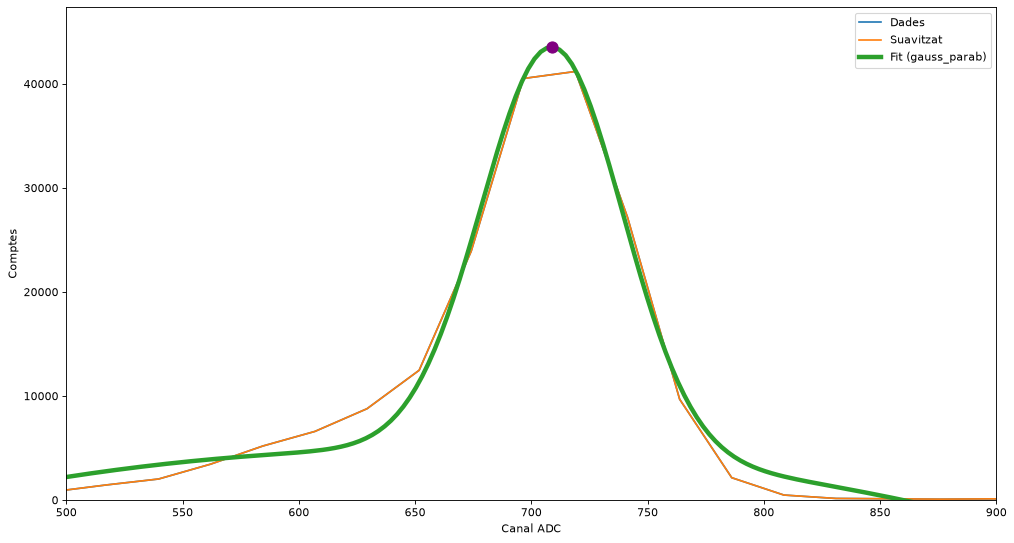

In [17]:
bin_centers_Am, counts_total_Am, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta="Data/241Am_LaBr_maj_nmaj4_LG12_36.5V_cgain15_1500s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl=500,
    xr=900,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=True,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=1500,
    fit_type="gauss_parab",
)

pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

### $^{133}\mathrm{Ba}$

--- Ajust (gauss_parab) ---
mu = 872.6824560457551 ± 0.9574340007997713
sigma = 28.865542067065842 ± 1.666368049323121
resolució = 7.788990898041714 ± 0.4497289279604088
àrea = 23659.398784373483 ± 1822.7790773157571


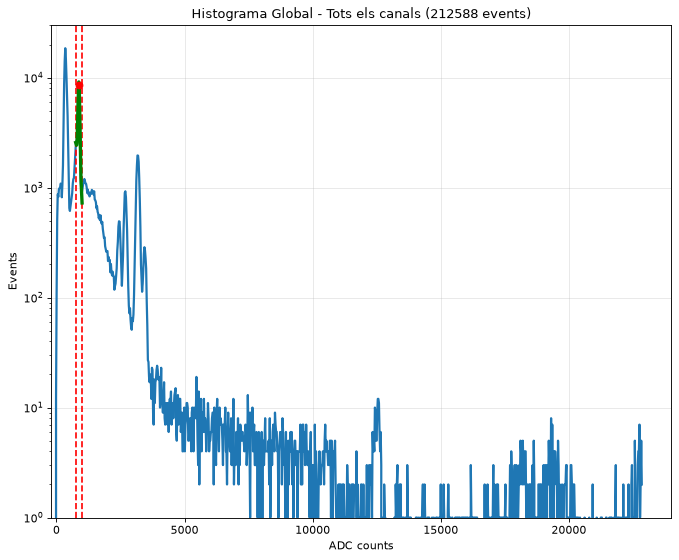

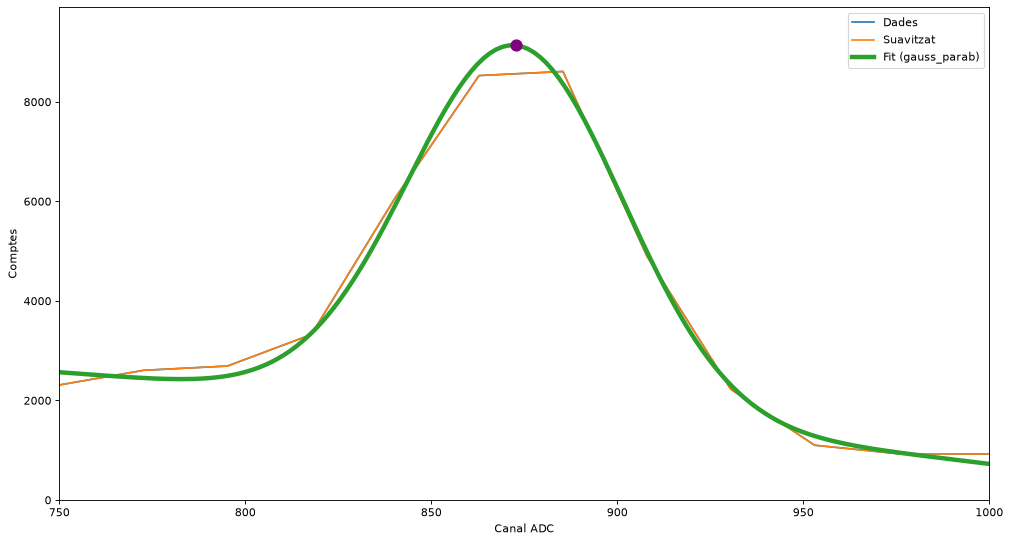

In [20]:
bin_centers_Ba, counts_total_Ba, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta=r"Data/133Ba_LaBr_maj_nmaj4_LG12_36.5V_1500s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl = 750,
    xr = 1000,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=False,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=1500,
    fit_type="gauss_parab"
)


pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

--- Ajust (gauss_parab) ---
mu = 3175.1252732434923 ± 0.48223720474085674
sigma = 54.11268521195722 ± 0.7980806927058383
resolució = 4.013247505582585 ± 0.05919250104156304
àrea = 11653.04964257633 ± 229.53165604057244


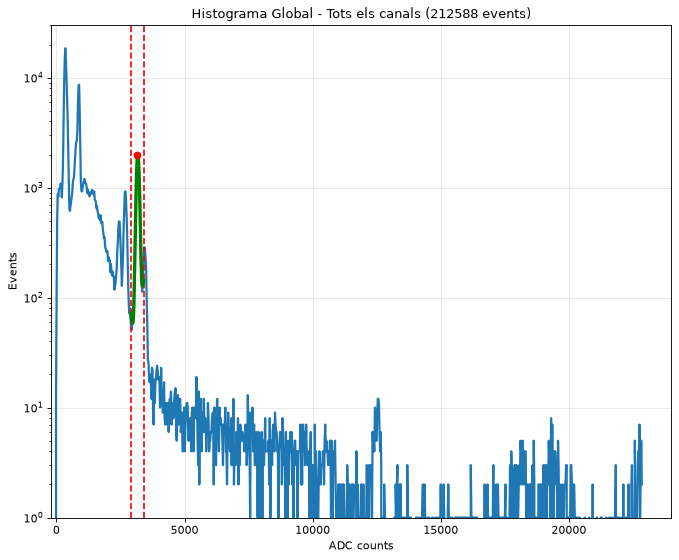

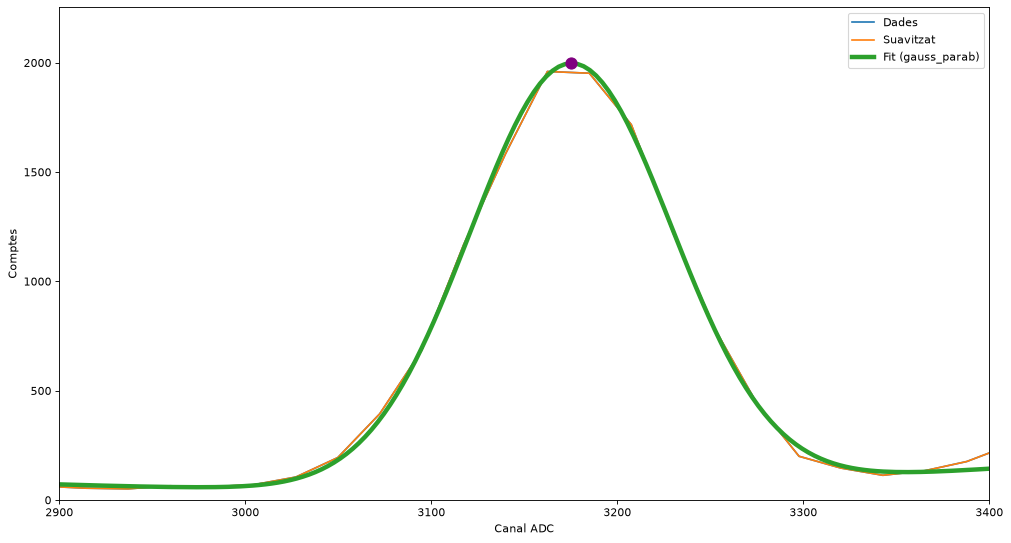

In [21]:
bin_centers, counts_total, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta=r"Data/133Ba_LaBr_maj_nmaj4_LG12_36.5V_1500s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl = 2900,
    xr = 3400,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=False,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=1500,
    fit_type="gauss_parab"
)

pics.append(np.array([magnituds[0],delta_magnituds[0],magnituds[3],delta_magnituds[3]]))

--- Ajust (gauss) ---
mu = 4597.652530988274 ± 0.2993085136752655
sigma = 66.83455500434306 ± 0.3253937003436527
resolució = 3.4231240565524153 ± 0.01666746452100094
àrea = 90563.61705692271 ± 568.4568784949458


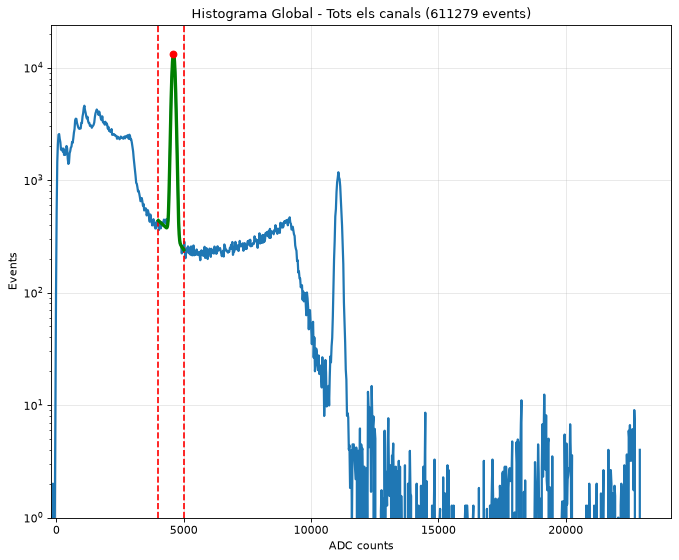

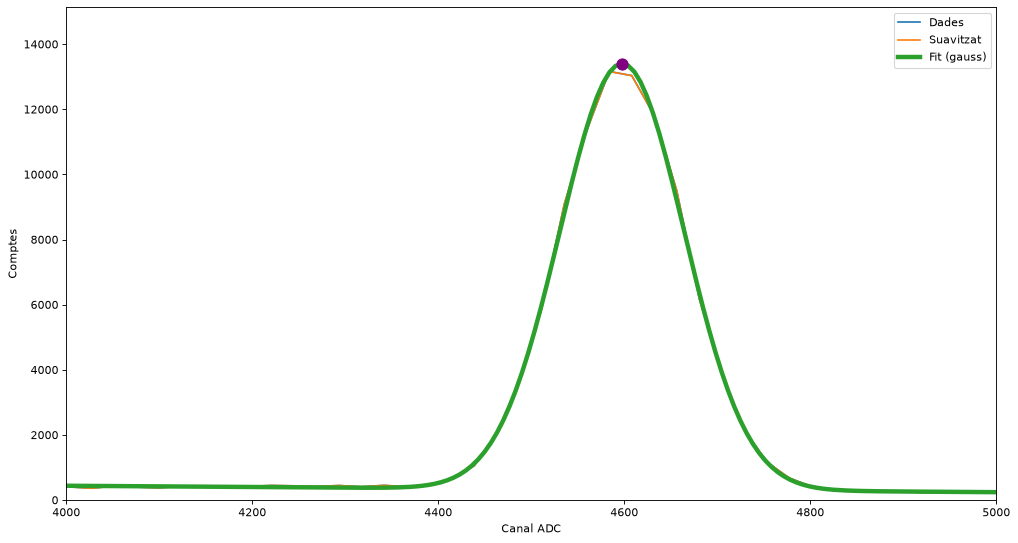

In [22]:
bin_centers_Na, counts_total_Na, magnituds, delta_magnituds = analysis.fit_gaussiana(
    ruta="Data/22Na_LaBr_maj_nmaj4_LG12_36.5V_3900s_merged.txt",
    asicid=1,
    smoothing_points=1,
    xl=4000,
    xr=5000,
    prominence_peak=20,
    fit_bool=True,
    subtract_bool=True,
    background_removal=True,
    pos_pedestal=pos_pedestal,
    ruta_bg=ruta_backgr,
    tbg=10800, tsrc=3900,
)


# Calibratge en energia

In [23]:
print(pics)
print(len(pics))

[array([1.01579269e+04, 1.00114248e+00, 2.45182671e+02, 2.90400918e+00]), array([1.13778292e+04, 8.14098719e-01, 2.61458152e+02, 2.41449507e+00]), array([5.94879093e+03, 7.27984148e-01, 1.71402423e+02, 1.86512807e+00]), array([1.10776038e+04, 8.57964565e-01, 2.17930488e+02, 2.24814502e+00]), array([708.96391127,   1.24106719,  71.1993209 ,   3.89908896]), array([708.96391127,   1.24106719,  71.1993209 ,   3.89908896]), array([872.68245605,   0.957434  ,  67.97315707,   3.92399688]), array([3.17512527e+03, 4.82237205e-01, 1.27425636e+02, 1.87933641e+00]), array([872.68245605,   0.957434  ,  67.97315707,   3.92399688]), array([3.17512527e+03, 4.82237205e-01, 1.27425636e+02, 1.87933641e+00])]
10


Pendent (m): 0.11801588517032491 pm 0.0009177366822331056
Ordenada a l'origen (b): -24.836753131082176 pm 6.955498840052154
Coeficient de correlació lineal (r): 0.9998488539495625
[1173.95997621 1317.92782977  677.21507462 1282.49646403   58.83225041
   78.15363939  349.87846652]
[11.63177716 12.54673071  8.84260436 12.31841495  6.98739948  7.00236821
  7.54143122]


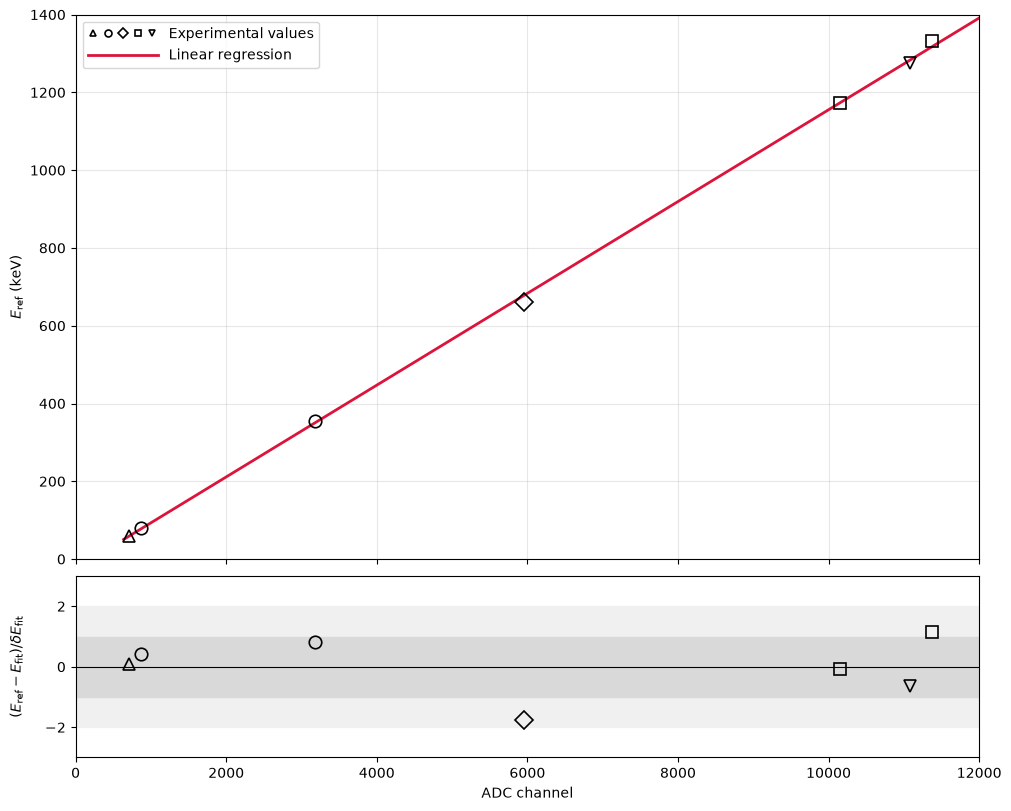

  1173.23 keV   E_fit =   1173.96 ± 11.63 keV   residuals =  -0.06 sigma
  1332.49 keV   E_fit =   1317.93 ± 12.55 keV   residuals =  +1.16 sigma
   661.65 keV   E_fit =    677.22 ± 8.84 keV   residuals =  -1.76 sigma
  1274.54 keV   E_fit =   1282.50 ± 12.32 keV   residuals =  -0.65 sigma
    59.54 keV   E_fit =     58.83 ± 6.99 keV   residuals =  +0.10 sigma
    81.00 keV   E_fit =     78.15 ± 7.00 keV   residuals =  +0.41 sigma
   356.01 keV   E_fit =    349.88 ± 7.54 keV   residuals =  +0.81 sigma


In [33]:
ener_teor = np.array([1173.228,1332.492,661.655,1274.537,59.5409,80.9979,356.0129])
adc = [array[0] for array in pics]
delta_adc = [array[1] for array in pics]


m_ener, dm_ener, b_ener, db_ener, ener, delta_ener = analysis.energy_calib(adc,ener_teor,delta_adc, save_fig_bool=True, output_filename='energy_calib_plot.pdf')

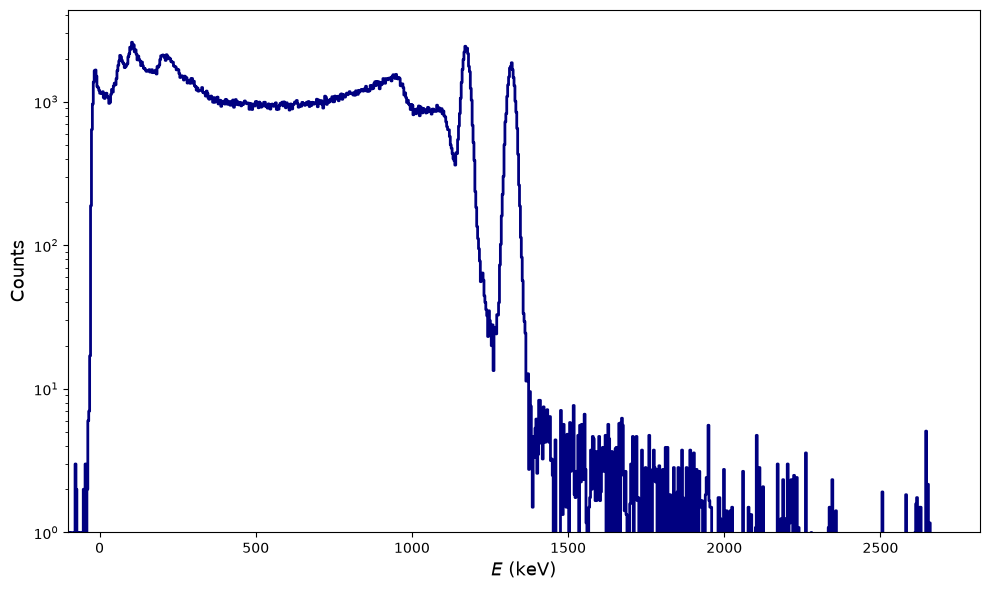

In [ ]:
from matplotlib.ticker import LogLocator

# ADC to energy
energy_bins = m_ener * np.array(bin_centers_Co) + b_ener


fig, ax = plt.subplots(figsize=(10, 6))

# Spectrum
ax.plot(energy_bins, counts_total_Co, color='navy', drawstyle='steps-mid', linewidth=2)

# Axis
ax.set_xlabel(r'$E$ (keV)', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.set_yscale('log')
ax.set_ylim(bottom=1)
ax.set_xlim(left=-100)



fig.tight_layout()
#functions.save_pdf(fig, 'espectre_Co60.pdf')  
plt.show()

np.savetxt(
    'Co_spec.txt',
    np.column_stack((energy_bins, counts_total_Co)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='Energy (keV)\tCounts',
    comments=''
)

np.savetxt(
    'Co_spec_ADC.txt',
    np.column_stack((bin_centers_Co, counts_total_Co)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='ADC channel\tCounts',
    comments=''
)

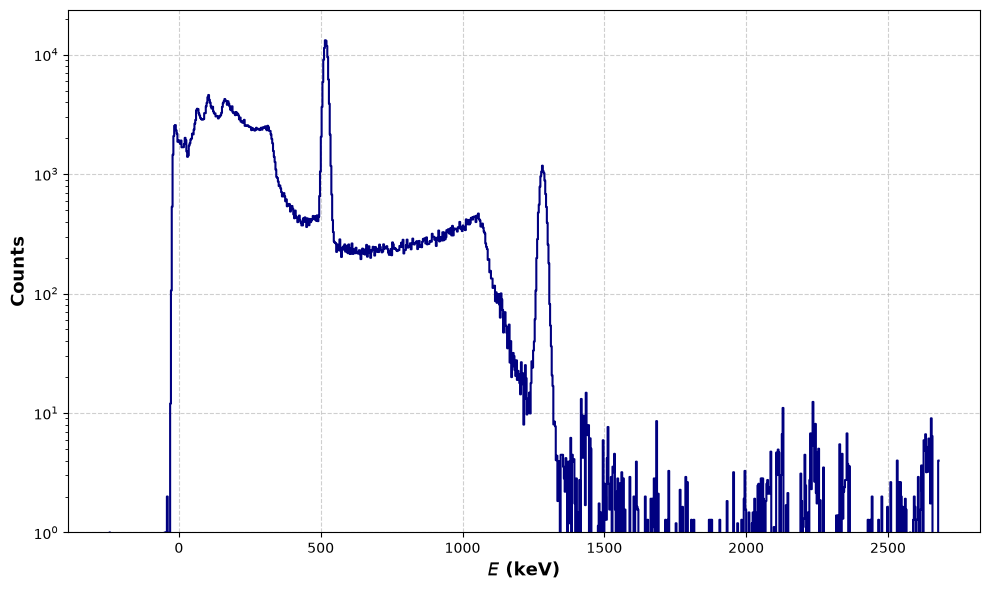

In [35]:
# 1. ADC to energy
energy_bins = m_ener * np.array(bin_centers_Na) + b_ener


plt.figure(figsize=(10, 6), dpi=100)


plt.plot(energy_bins, counts_total_Na, color='navy', drawstyle='steps-mid')


plt.xlabel('$E$ (keV)', fontsize=13, fontweight='bold')
plt.ylabel('Counts', fontsize=13, fontweight='bold')


plt.grid(True, linestyle='--', alpha=0.6)
plt.yscale('log')
plt.ylim(bottom=1)
plt.tight_layout()
#plt.savefig("Na_test.pdf", bbox_inches="tight") 


plt.show()

np.savetxt(
    'Na_spec.txt',
    np.column_stack((energy_bins, counts_total_Na)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='Energy (keV)\tCounts',
    comments=''
)

np.savetxt(
    'Na_spec_ADC.txt',
    np.column_stack((bin_centers_Na, counts_total_Na)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='ADC channel\tCounts',
    comments=''
)

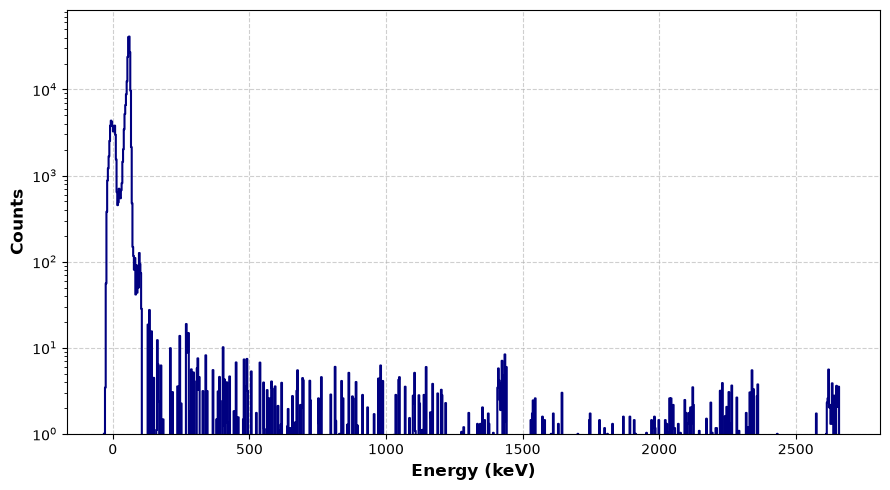

In [36]:
# ADC to energy
energy_bins = m_ener * np.array(bin_centers_Am) + b_ener


plt.figure(figsize=(9, 5), dpi=100)


plt.plot(energy_bins, counts_total_Am, color='navy', drawstyle='steps-mid')


plt.xlabel('Energy (keV)', fontsize=12, fontweight='bold')
plt.ylabel('Counts', fontsize=12, fontweight='bold')


plt.grid(True, linestyle='--', alpha=0.6)
plt.yscale('log')
plt.ylim(bottom=1)
plt.tight_layout()

plt.show()

np.savetxt(
    'Am_spec.txt',
    np.column_stack((energy_bins, counts_total_Am)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='Energy (keV)\tCounts',
    comments=''
)

np.savetxt(
    'Am_spec_ADC.txt',
    np.column_stack((bin_centers_Am, counts_total_Am)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='ADC channel\tCounts',
    comments=''
)

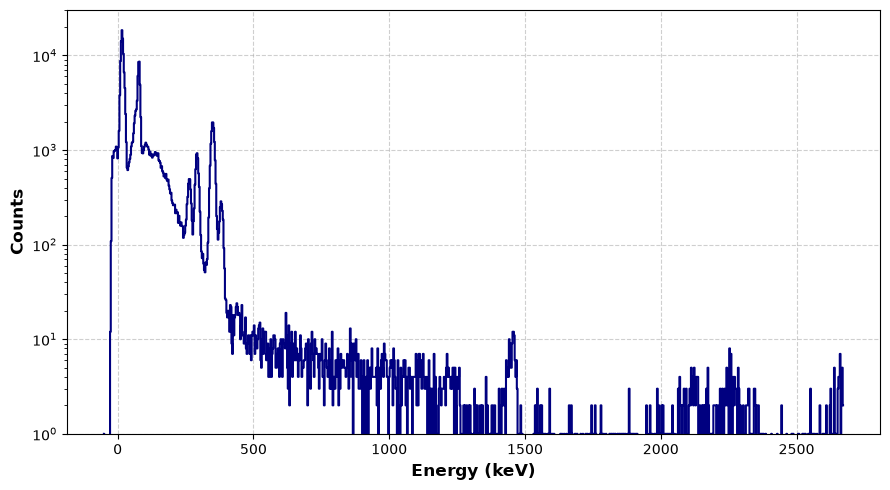

In [37]:
# 1. ADC to energy
energy_bins = m_ener * np.array(bin_centers_Ba) + b_ener


plt.figure(figsize=(9, 5), dpi=100)


plt.plot(energy_bins, counts_total_Ba, color='navy', drawstyle='steps-mid')


plt.xlabel('Energy (keV)', fontsize=12, fontweight='bold')
plt.ylabel('Counts', fontsize=12, fontweight='bold')
#plt.title('Espectre de $^{133}$Ba (Calibrat en energia)', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.6)
plt.yscale('log')
plt.ylim(bottom=1)
plt.tight_layout()
plt.show()

np.savetxt(
    'Ba_spec.txt',
    np.column_stack((energy_bins, counts_total_Ba)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='Energy (keV)\tCounts',
    comments=''
)

np.savetxt(
    'Ba_spec_ADC.txt',
    np.column_stack((bin_centers_Ba, counts_total_Ba)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='ADC channel\tCounts',
    comments=''
)

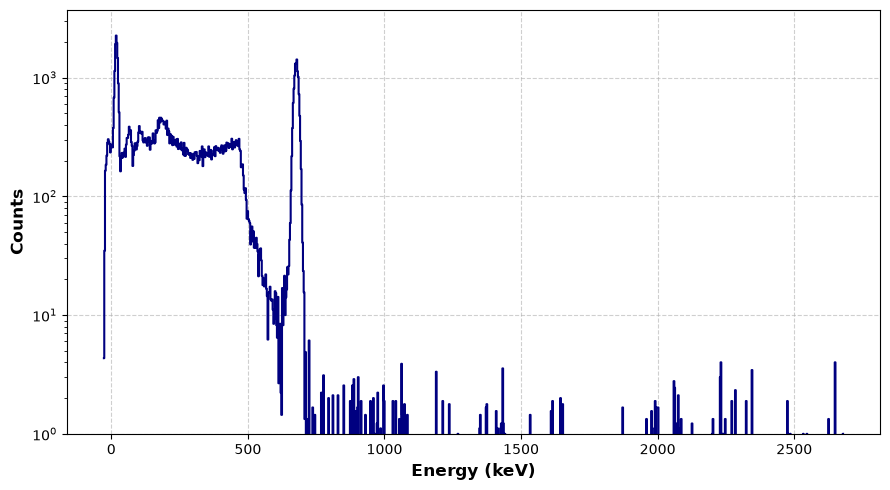

In [38]:
# ADC to energy
energy_bins = m_ener * np.array(bin_centers_Cs) + b_ener


plt.figure(figsize=(9, 5), dpi=100)


plt.plot(energy_bins, counts_total_Cs, color='navy', drawstyle='steps-mid')


plt.xlabel('Energy (keV)', fontsize=12, fontweight='bold')
plt.ylabel('Counts', fontsize=12, fontweight='bold')


plt.grid(True, linestyle='--', alpha=0.6)
plt.yscale('log')
plt.ylim(bottom=1)
plt.tight_layout()
plt.show()

np.savetxt(
    'Cs_spec.txt',
    np.column_stack((energy_bins, counts_total_Cs)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='Energy (keV)\tCounts',
    comments=''
)

np.savetxt(
    'Cs_spec_ADC.txt',
    np.column_stack((bin_centers_Cs, counts_total_Cs)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='ADC channel\tCounts',
    comments=''
)

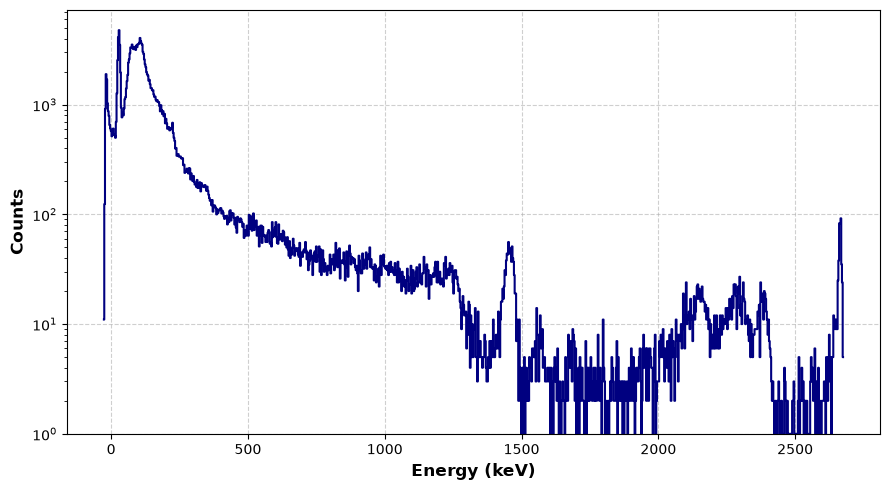

In [39]:
# ADC to energy
energy_bins = m_ener * np.array(background_bins) + b_ener


plt.figure(figsize=(9, 5), dpi=100)


plt.plot(energy_bins, background_counts, color='navy', drawstyle='steps-mid')


plt.xlabel('Energy (keV)', fontsize=12, fontweight='bold')
plt.ylabel('Counts', fontsize=12, fontweight='bold')


plt.grid(True, linestyle='--', alpha=0.6)
plt.yscale('log')
plt.ylim(bottom=1)
plt.tight_layout()
plt.show()


np.savetxt(
    'background_spec.txt',
    np.column_stack((energy_bins, background_counts)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='Energy (keV)\tCounts',
    comments=''
)

np.savetxt(
    'background_spec_ADC.txt',
    np.column_stack((background_bins, background_counts)),
    delimiter='\t',
    fmt=['%.4f', '%d'],
    header='ADC channel\tCounts',
    comments=''
)

# Resolució en energia

m_e = 0.5930 ± 0.0087 keV
b_e = 22.4162 ± 4.9769 keV^2
r = 0.970601   (r^2 = 0.942067)
R(E) = 100 * sqrt(0.5930 * E + 22.4162) / E


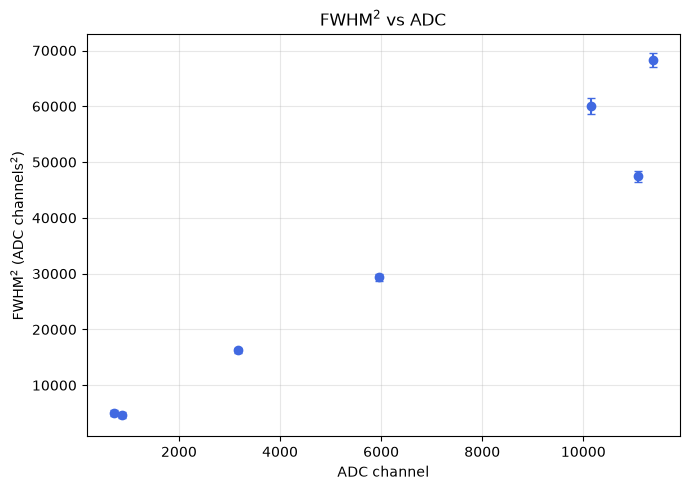

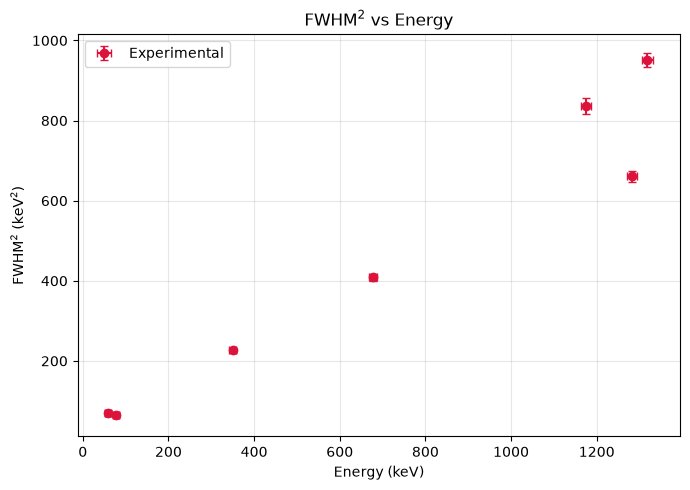

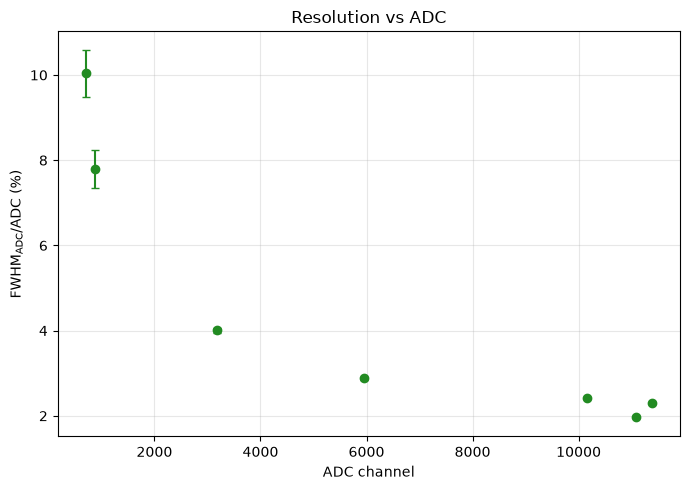

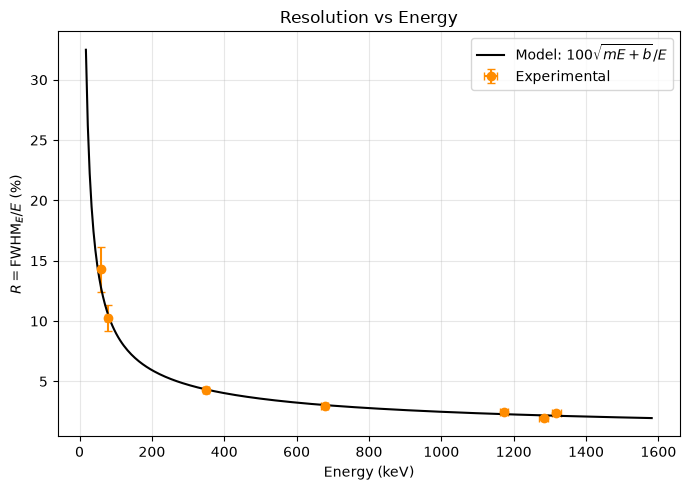

R: [ 2.46477312  2.34126745  2.98696963  2.00540587 14.28238903 10.26428502
  4.29813511]
delta R: [0.03806125 0.03105261 0.05076986 0.02826655 1.86793055 1.09401584
 0.11225554]


In [ ]:
adc = [array[0] for array in pics]
delta_adc = [array[1] for array in pics]

fwhm = [array[2] for array in pics]
delta_fwhm = [array[3] for array in pics]

resol_ener, delta_resol_ener, fwhm_ener, delta_fwhm_ener, resol_adc, delta_resol_adc, m_e, delta_m_e, b_e, delta_b_e = analysis.energy_res(fwhm, delta_fwhm, adc, delta_adc, ener, delta_ener,
                    m_ener, analysis.recta)

print(f"E: {ener}")
print(f"R: {resol_ener}")
print(f"delta R: {delta_resol_ener}")